In [289]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, f1_score, ConfusionMatrixDisplay

from scipy.stats import shapiro
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [290]:
df=pd.read_csv('data/telecom_customers_ispravljen.csv',na_values=[' ','','-'])
display((df.head()))
df.info()

,customer_id,customer_name,region,age,tenure_months,contract_type,internet_service,monthly_charge_eur,total_charges_eur,support_calls,late_payments,auto_pay,has_bundle,satisfaction_score,data_usage_gb,complaints,cancelled
0,TEL-00001,Mina Nikolić,Južna Srbija,33.0,12,godišnji,DSL,35.28,380.57,1,2,0,1,3.0,110.6,0,1
1,TEL-00002,Marko Pavlović,Južna Srbija,36.0,2,godišnji,optički,80.91,149.42,0,1,0,0,5.0,193.8,0,0
2,TEL-00003,Stefan Savić,Šumadija,36.0,14,mesečni,DSL,13.01,NaN,1,1,0,0,5.0,37.0,0,1
3,TEL-00004,Ana Đorđević,Beograd,73.0,3,mesečni,mobilni,40.62,128.82,0,1,0,0,3.0,67.7,0,1
4,TEL-00005,Mina Marković,Zapadna Srbija,48.0,40,godišnji,mobilni,29.94,1085.21,1,0,0,1,4.0,8.7,0,1


<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         8000 non-null   str    
 1   customer_name       8000 non-null   str    
 2   region              7905 non-null   str    
 3   age                 7928 non-null   float64
 4   tenure_months       8000 non-null   int64  
 5   contract_type       8000 non-null   str    
 6   internet_service    8000 non-null   str    
 7   monthly_charge_eur  8000 non-null   float64
 8   total_charges_eur   6680 non-null   float64
 9   support_calls       8000 non-null   int64  
 10  late_payments       8000 non-null   int64  
 11  auto_pay            8000 non-null   int64  
 12  has_bundle          8000 non-null   int64  
 13  satisfaction_score  7740 non-null   float64
 14  data_usage_gb       7850 non-null   float64
 15  complaints          8000 non-null   int64  
 16  cancelled        

In [291]:
print('varijabla cancelled ima na vrednosti ',df['cancelled'].isna().sum())

df['Retained']=np.where(df['cancelled']==0,'Yes','No')
df['Retained']=df['Retained'].map({'Yes':1,'No':0})
df.drop(columns='cancelled',inplace=True)

varijabla cancelled ima na vrednosti  0


In [292]:
print('variajbla age ima na vrednosti ',df['age'].isna().sum())
print((df.isna().mean()*100).round(2))

df['age']=df['age'].fillna(df['age'].median())
print('varijabla age ima na vrednosti ',df['age'].isna().sum())


variajbla age ima na vrednosti  72
customer_id            0.00
customer_name          0.00
region                 1.19
age                    0.90
tenure_months          0.00
contract_type          0.00
internet_service       0.00
monthly_charge_eur     0.00
total_charges_eur     16.50
support_calls          0.00
late_payments          0.00
auto_pay               0.00
has_bundle             0.00
satisfaction_score     3.25
data_usage_gb          1.88
complaints             0.00
Retained               0.00
dtype: float64
varijabla age ima na vrednosti  0


In [293]:
print('pre ',len(df))
df=df[df['age']<=85]
print('sad ',len(df))

df.isna().sum()

df['region']=df['region'].fillna(df['region'].mode()[0])
df['satisfaction_score']=df['satisfaction_score'].fillna(df['satisfaction_score'].median())
df['data_usage_gb']=df['data_usage_gb'].fillna(df['data_usage_gb'].median())

df.isna().sum()
df.drop(columns=['customer_name','customer_id','total_charges_eur'],inplace=True)


pre  8000
sad  7983


In [294]:
df.info()


<class 'pandas.DataFrame'>
Index: 7983 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   region              7983 non-null   str    
 1   age                 7983 non-null   float64
 2   tenure_months       7983 non-null   int64  
 3   contract_type       7983 non-null   str    
 4   internet_service    7983 non-null   str    
 5   monthly_charge_eur  7983 non-null   float64
 6   support_calls       7983 non-null   int64  
 7   late_payments       7983 non-null   int64  
 8   auto_pay            7983 non-null   int64  
 9   has_bundle          7983 non-null   int64  
 10  satisfaction_score  7983 non-null   float64
 11  data_usage_gb       7983 non-null   float64
 12  complaints          7983 non-null   int64  
 13  Retained            7983 non-null   int64  
dtypes: float64(4), int64(7), str(3)
memory usage: 935.5 KB


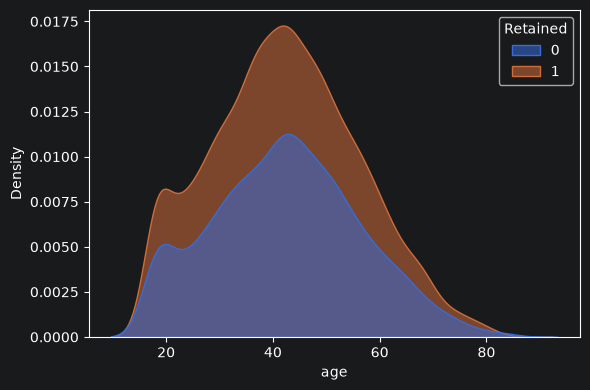

In [295]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='age',hue='Retained',fill=True,alpha=0.55)
plt.tight_layout()
plt.show()
df.drop(columns='age',inplace=True)

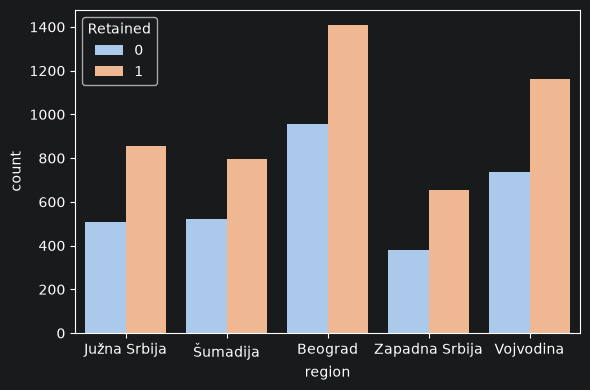

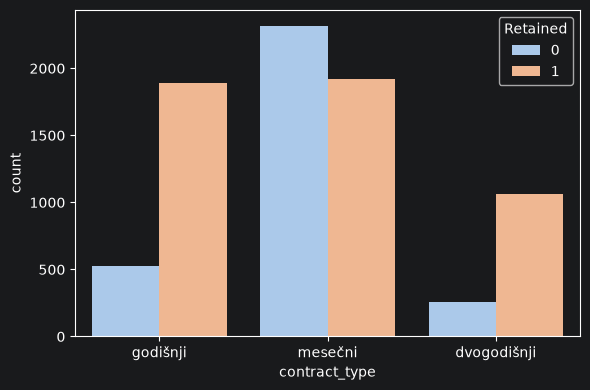

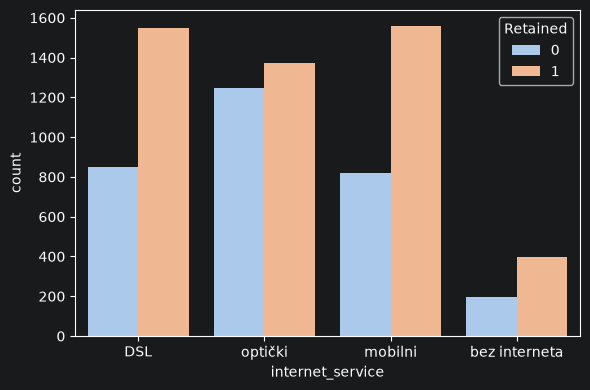

In [296]:
for col in ['region','contract_type','internet_service']:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df,x=col,hue='Retained',palette='pastel')
    plt.tight_layout()
    plt.show()
df.drop(columns='region',inplace=True)

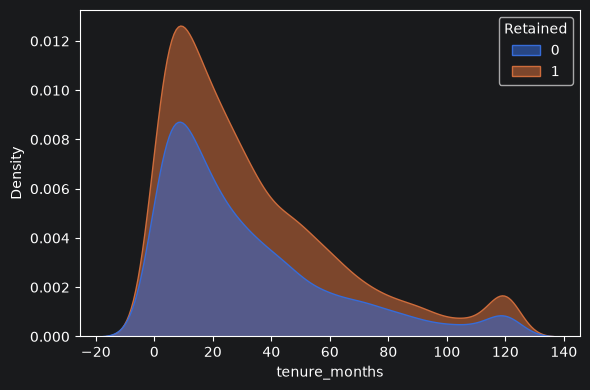

In [297]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='tenure_months',hue='Retained',fill=True,alpha=0.55)
plt.tight_layout()
plt.show()
df.drop(columns='tenure_months',inplace=True)

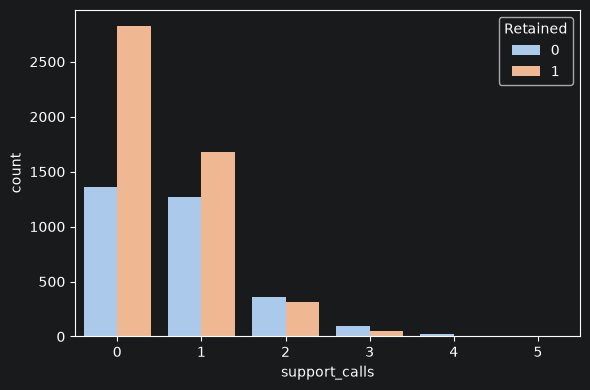

In [298]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='support_calls',hue='Retained',palette='pastel')
plt.tight_layout()
plt.show()


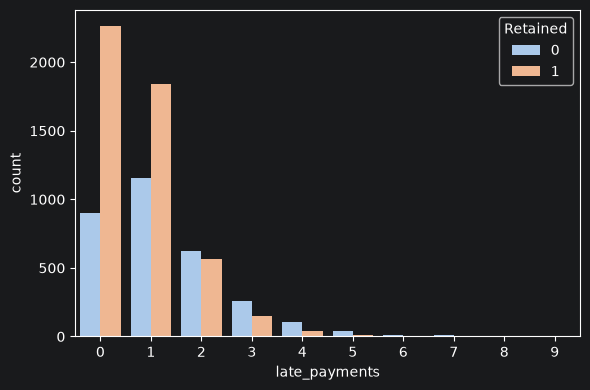

In [299]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='late_payments',hue='Retained',palette='pastel')
plt.tight_layout()
plt.show()


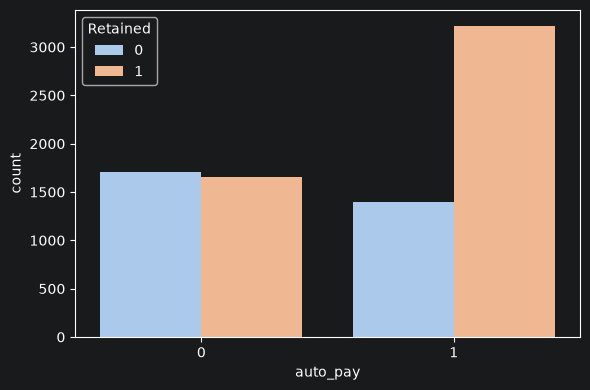

In [300]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='auto_pay',hue='Retained',palette='pastel')
plt.tight_layout()
plt.show()


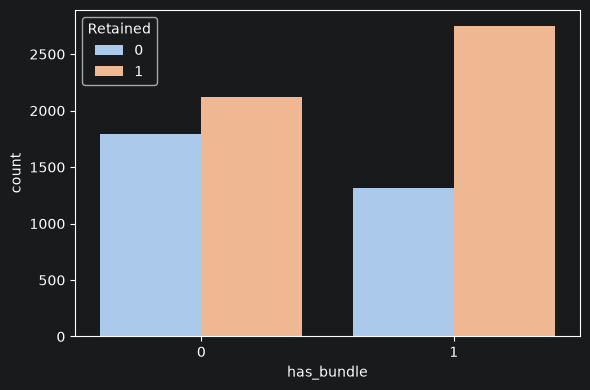

In [301]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='has_bundle',hue='Retained',palette='pastel')
plt.tight_layout()
plt.show()



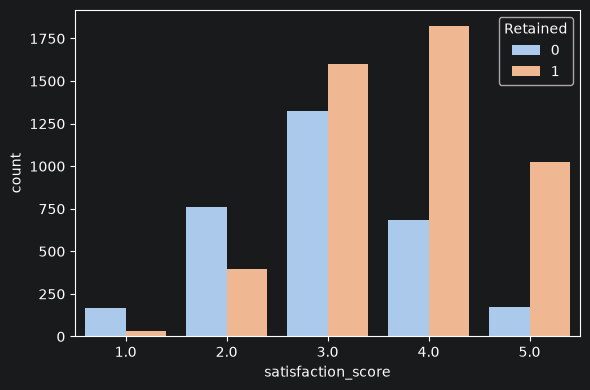

In [302]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='satisfaction_score',hue='Retained',palette='pastel')
plt.tight_layout()
plt.show()


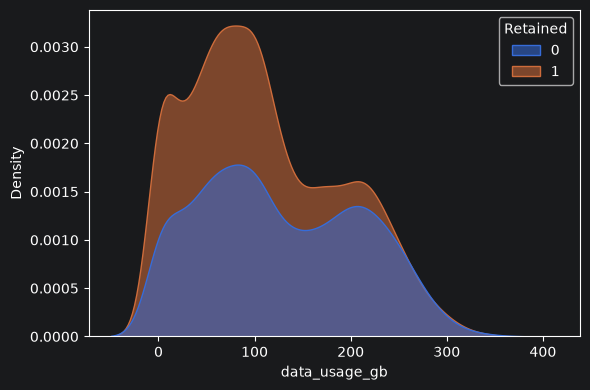

In [303]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df,x='data_usage_gb',hue='Retained',fill=True,alpha=0.55)
plt.tight_layout()
plt.show()

df.drop(columns='data_usage_gb',inplace=True)

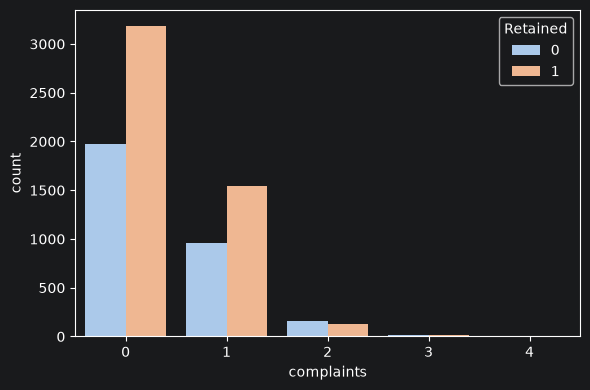

In [304]:
plt.figure(figsize=(6,4))
sns.countplot(data=df,x='complaints',hue='Retained',palette='pastel')
plt.tight_layout()
plt.show()

In [305]:
print(df['contract_type'].nunique())
df['contract_type']=df['contract_type'].map({'mesečni':0, 'godišnji':1,'dvogodišnji':2})

from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(sparse_output=False,drop='first')
cats=['internet_service']
encoded_array=ohe.fit_transform(df[cats])
encoded_col=ohe.get_feature_names_out(cats)

df_ohe=pd.DataFrame(encoded_array,columns=encoded_col,index=df.index)
df=df.drop(columns=cats).join(df_ohe)

display(df.head(5))

3


,contract_type,monthly_charge_eur,support_calls,late_payments,auto_pay,has_bundle,satisfaction_score,complaints,Retained,internet_service_bez interneta,internet_service_mobilni,internet_service_optički
0,1,35.28,1,2,0,1,3.0,0,0,0.0,0.0,0.0
1,1,80.91,0,1,0,0,5.0,0,1,0.0,0.0,1.0
2,0,13.01,1,1,0,0,5.0,0,0,0.0,0.0,0.0
3,0,40.62,0,1,0,0,3.0,0,0,0.0,1.0,0.0
4,1,29.94,1,0,0,1,4.0,0,0,0.0,1.0,0.0


In [306]:
X=df.drop(columns='Retained')
y=df['Retained']

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


Retained
1    0.610868
0    0.389132
Name: proportion, dtype: float64
Retained
1    0.61052
0    0.38948
Name: proportion, dtype: float64


In [307]:
param_grid={'ccp_alpha':np.arange(0.00, 0.05, 0.0025)}
cv=StratifiedKFold(n_splits=10,shuffle=True,random_state=42)
grid=GridSearchCV(DecisionTreeClassifier(random_state=42),
                  cv=cv,
                  param_grid=param_grid,
                  scoring='accuracy')

grid.fit(X_train,y_train)

best=grid.best_params_['ccp_alpha']
print(best)

0.0025


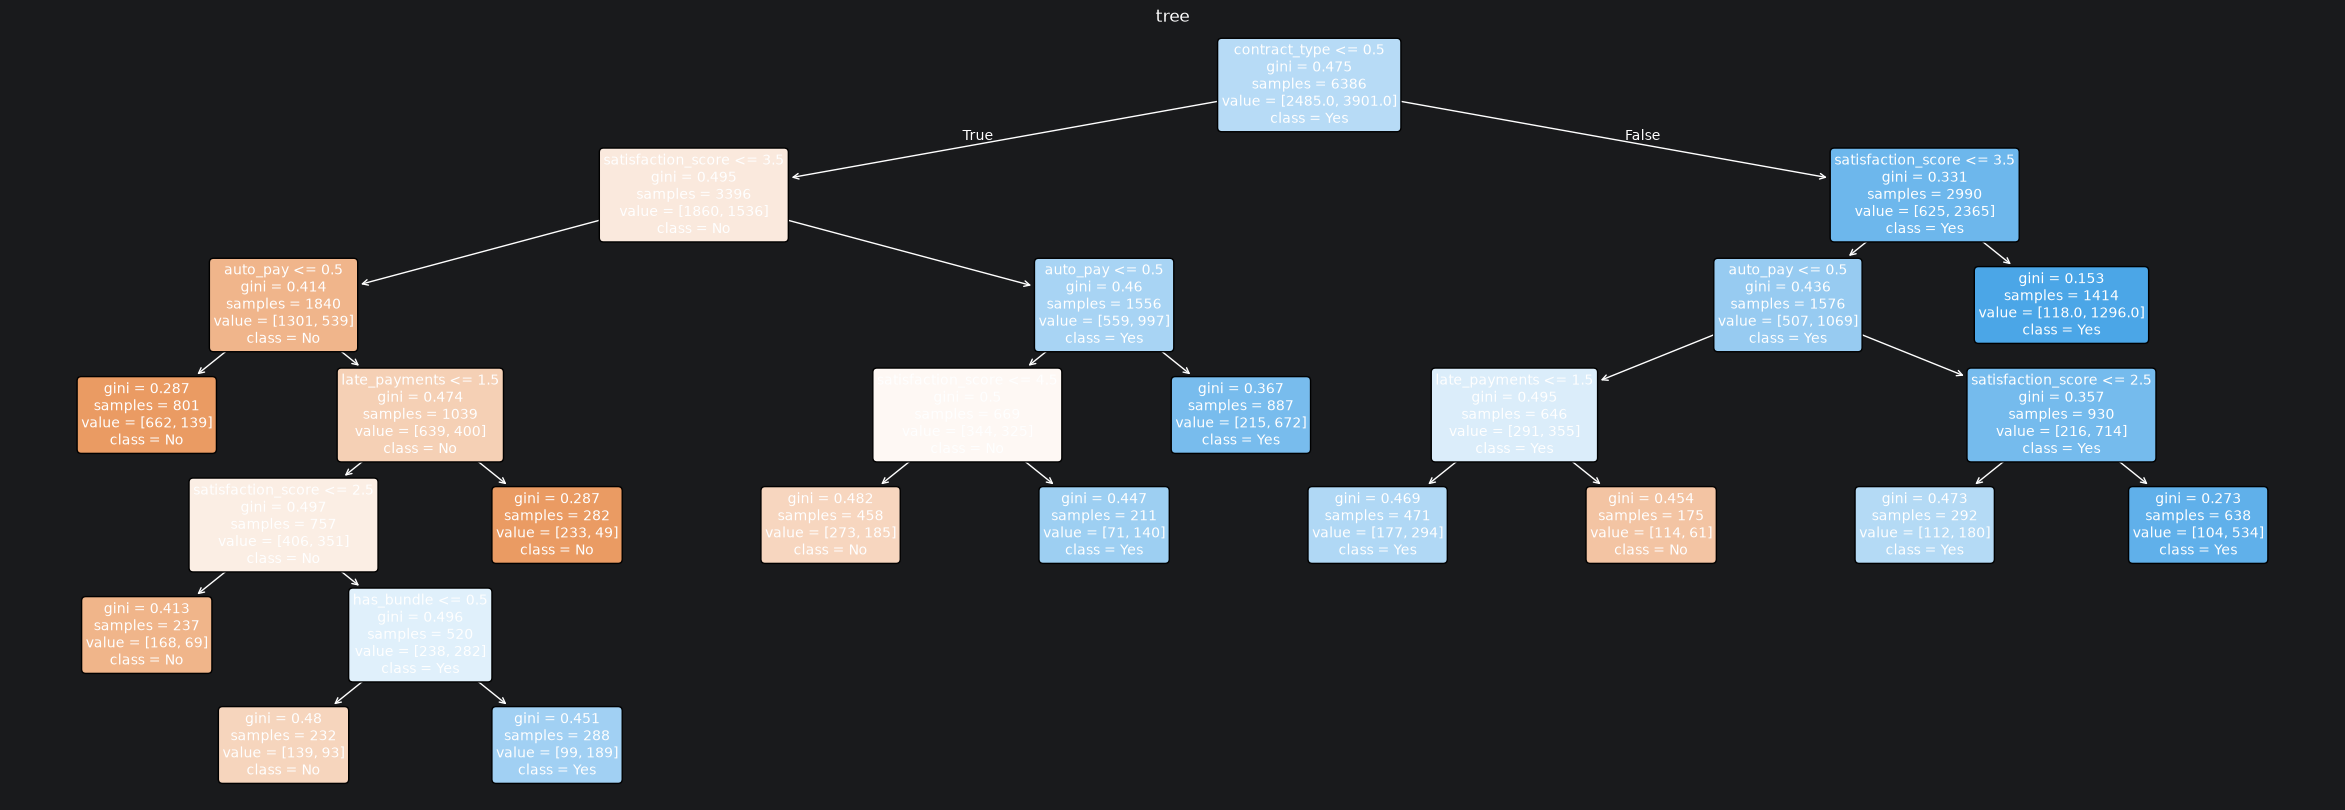

In [308]:
tree=DecisionTreeClassifier(ccp_alpha=best,random_state=42)
tree.fit(X_train,y_train)

plt.figure(figsize=[30,10])
plot_tree(tree,
          feature_names=X_train.columns,
          class_names=['No','Yes'],
          rounded=True,
          fontsize=10,
          filled=True)
plt.title('tree')
plt.show()


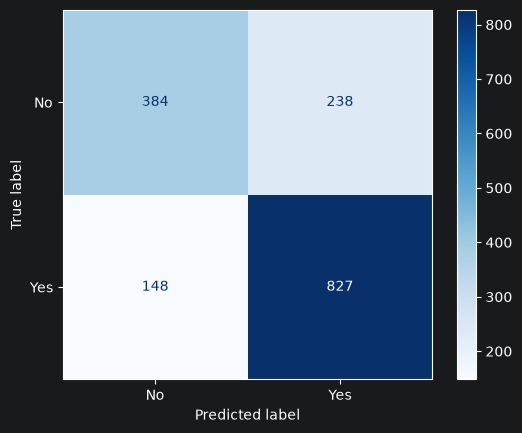

In [309]:
y_pred=tree.predict(X_test)

cm=confusion_matrix(y_test,y_pred)
cm_plot=ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No','Yes'])
cm_plot.plot(cmap=plt.cm.Blues)
plt.show()

In [310]:
def compute_basic_eval_measures(y_true,y_pred):
    acc=accuracy_score(y_true, y_pred)
    pre=precision_score(y_true, y_pred,pos_label=1)
    recall=recall_score(y_true, y_pred,pos_label=1)
    f1=f1_score(y_true, y_pred,pos_label=1)
    return {'acc':acc,
            'pre': pre,
            'recall':recall,
            'f1':f1 }


In [311]:
eval=compute_basic_eval_measures(y_test,y_pred)
eval

{'acc': 0.7582968065122104,
 'pre': 0.7765258215962442,
 'recall': 0.8482051282051282,
 'f1': 0.8107843137254902}